# Quando esse deal vai fechar?

**Isabela Class** · estudo em andamento · base pública e sintética [Maven CRM Sales Opportunities](https://mavenanalytics.io/data-playground)

Errar o *quando* de um negócio não faz a receita sumir: empurra ela de um mês, ou de um trimestre, para outro. É isso que estoura uma meta. Este notebook parte dessa pergunta e chega a uma previsão de receita mensal testada contra o que de fato aconteceu.

Aqui, **fechar é ganhar**: o negócio vira receita. Quando ele sai do funil, ganho ou perdido, digo que foi **encerrado**; o que nunca é ganho nem perdido fica **parado**.

**O que este estudo encontrou**

1. O tempo até o ganho tem dois grupos: 42% dos ganhos saem em até 20 dias e 54% levam de 45 a 138 dias. A média (52 dias) não descreve quase ninguém.
2. Contando os negócios abertos, de cada 100 que entram em negociação, cerca de 51 são ganhos, 32 perdidos e 16 ficam parados para sempre. Depois de 138 dias aberto, nenhum negócio foi ganho.
3. O que decide o *quando* é a idade do negócio e o mês do trimestre. Produto, vendedor, regional e porte da conta não melhoram a previsão.
4. Num teste retroativo em sete datas de corte, a previsão mensal errou em média 13%. A conta tradicional (pipeline × taxa de ganho) erra por três vezes.
5. Um alarme simples encontrou uma regional que triplicou o pipeline em três semanas com negócios que ficaram parados, e descontá-los melhorou a previsão.

**Como rodar:** coloque os cinco CSVs da base na pasta `data/` (veja `data/README.md`) e rode as células em ordem. No Google Colab, a primeira célula clona o repositório.

In [1]:
# No Colab: clona o repositório e entra na pasta dos notebooks
import os, sys
if "google.colab" in sys.modules and not os.path.exists("when-will-this-deal-close"):
    !git clone https://github.com/isabelaclass/when-will-this-deal-close
    %cd when-will-this-deal-close/notebooks
    print("Agora envie os 5 CSVs para a pasta data/ (painel de arquivos à esquerda).")

In [2]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import roc_auc_score

from deal.dados import ler_tabelas, limpar, carregar, INI, FIM, mes_tri
from deal.modelos import rodar, Naive, Idade, IdadeCal, GBM
from deal.alarme import detectar, rodar_ajustado

pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
ROSA, TINTA, LARANJA = "#c2185b", "#2b1026", "#ff7a2f"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})

## 1. Os dados e a limpeza

São quatro tabelas: negócios (`sales_pipeline`), contas, produtos e vendedores. A limpeza segue quatro perguntas feitas a cada coluna: está faltando? está escrito de jeitos diferentes? o valor é possível? as tabelas conversam?

In [3]:
bruto = ler_tabelas()
for nome, df in bruto.items():
    print(f"{nome:10s} {df.shape[0]:>5} linhas  {df.shape[1]} colunas")
p = bruto["pipeline"]
p.head()

pipeline    8800 linhas  8 colunas
accounts      85 linhas  7 colunas
products       7 linhas  3 colunas
teams         35 linhas  3 colunas


,opportunity_id,sales_agent,product,account,deal_stage,engage_date,close_date,close_value
0,1C1I7A6R,Moses Frase,GTX Plus Basic,Cancity,Won,2016-10-20,2017-03-01,"1,054.000"
1,Z063OYW0,Darcel Schlecht,GTXPro,Isdom,Won,2016-10-25,2017-03-11,"4,514.000"
2,EC4QE1BX,Darcel Schlecht,MG Special,Cancity,Won,2016-10-25,2017-03-07,50.000
3,MV1LWRNH,Moses Frase,GTX Basic,Codehow,Won,2016-10-25,2017-03-09,588.000
4,PE84CX4O,Zane Levy,GTX Basic,Hatfan,Won,2016-10-25,2017-03-02,517.000


**Está faltando?** Os vazios têm explicação: valor e data de encerramento (`close_date`) só faltam nos negócios abertos, e Prospecting não tem data nenhuma. A conta vazia aparece só em negócios abertos.

In [4]:
p.groupby("deal_stage")[["account", "engage_date", "close_date", "close_value"]].apply(lambda d: d.isna().sum())

,account,engage_date,close_date,close_value
deal_stage,,,,
Engaging,1088,0,1589,1589
Lost,0,0,0,0
Prospecting,337,500,500,500
Won,0,0,0,0


**Está escrito de jeitos diferentes? As tabelas conversam?** O mesmo produto aparece como `GTXPro` no pipeline e `GTX Pro` na tabela de produtos; nas contas, há `technolgy` e `Philipines`. Cinco vendedores cadastrados não têm nenhum negócio.

In [5]:
print("produtos só no pipeline:", sorted(set(p["product"]) - set(bruto["products"]["product"])))
print("contas desconhecidas:", sorted(set(p.account.dropna()) - set(bruto["accounts"].account)))
print("vendedores sem negócio:", sorted(set(bruto["teams"].sales_agent) - set(p.sales_agent)))
print("setores:", sorted(bruto["accounts"].sector.unique()))

produtos só no pipeline: ['GTXPro']
contas desconhecidas: []
vendedores sem negócio: ['Carl Lin', 'Carol Thompson', 'Elizabeth Anderson', 'Mei-Mei Johns', 'Natalya Ivanova']
setores: ['employment', 'entertainment', 'finance', 'marketing', 'medical', 'retail', 'services', 'software', 'technolgy', 'telecommunications']


**O valor é possível?** Nenhum negócio é encerrado antes de entrar em negociação, nenhum leva mais de 138 dias para ser encerrado, e os encerramentos só existem entre 01/03/2017 e 31/12/2017. Guarde esse último ponto: ele volta na seção 5.

In [6]:
dur = (p.close_date - p.engage_date).dt.days
print("dias até o encerramento: mínimo", dur.min(), "| máximo", dur.max())
print("entradas em Engaging:", p.engage_date.min().date(), "a", p.engage_date.max().date())
print("encerramentos:", p.close_date.min().date(), "a", p.close_date.max().date())
e = carregar()   # aplica a limpeza e mantém os negócios que já entraram em negociação
print("\nnegócios analisados:", len(e))
e.deal_stage.value_counts()

dias até o encerramento: mínimo 1.0 | máximo 138.0
entradas em Engaging: 2016-10-20 a 2017-12-27
encerramentos: 2017-03-01 a 2017-12-31

negócios analisados: 8300


deal_stage
Won         4238
Lost        2473
Engaging    1589
Name: count, dtype: int64

## 2. Três hipóteses de partida

Antes de olhar os dados, anotei o que eu esperava encontrar, pela experiência em Sales Ops.

**Hipótese 1: negócio que anda rápido no funil converte mais.** Os dados mostram o contrário entre os encerrados: sair do funil rápido é, mais vezes, perder rápido. No extremo, a ideia vale: depois de 138 dias, nenhum negócio foi ganho.

In [7]:
c = e[e.ev > 0].copy()   # negócios encerrados: ganhos (ev = 1) ou perdidos (ev = 2)
c["won"] = (c.ev == 1).astype(int)
c["rapido"] = np.where(c.t <= 20, "até 20 dias", "mais de 20 dias")
c.groupby("rapido").agg(negocios=("won", "size"), taxa_de_ganho=("won", "mean"))

,negocios,taxa_de_ganho
rapido,,
até 20 dias,3095,0.569
mais de 20 dias,3616,0.685


**Hipótese 2: ticket alto alavanca a receita.** Vale para produto: os três produtos acima de 3.000 são 44% dos negócios encerrados e 84% da receita, com a mesma taxa de ganho e o mesmo tempo dos baratos. Não vale para o porte da conta (medido por funcionários): o ticket quase não muda, e a diferença de tempo e de conversão entre portes não se distingue do acaso.

In [8]:
rec = c.close_value.sum()
prod = c.groupby("product").agg(preco=("sales_price", "first"), negocios=("won", "size"),
                                taxa_de_ganho=("won", "mean"), receita=("close_value", "sum")).sort_values("preco")
prod["parte_dos_negocios"] = prod.negocios / prod.negocios.sum()
prod["parte_da_receita"] = prod.receita / rec
prod

,preco,negocios,taxa_de_ganho,receita,parte_dos_negocios,parte_da_receita
product,,,,,,
MG Special,55,1223,0.648,"43,768.000",0.182,0.004
GTX Basic,550,1436,0.637,"499,263.000",0.214,0.050
GTX Plus Basic,1096,1051,0.621,"705,275.000",0.157,0.070
MG Advanced,3393,1084,0.603,"2,216,387.000",0.162,0.222
GTX Pro,4821,1147,0.636,"3,510,578.000",0.171,0.351
GTX Plus Pro,5482,745,0.643,"2,629,651.000",0.111,0.263
GTK 500,26768,25,0.600,"400,612.000",0.004,0.040


In [9]:
contas = limpar(bruto)["accounts"]
contas["porte"] = pd.cut(contas.employees, [0, 1000, 5000, 1e9], right=False, labels=["até 999", "1.000 a 4.999", "5.000+"])
cp = c.merge(contas[["account", "porte"]], on="account")
print(cp.groupby("porte", observed=True).agg(contas=("account", "nunique"), negocios=("won", "size"), taxa_de_ganho=("won", "mean"),
      ticket=("close_value", lambda s: s[s > 0].mean()), dias_mediana=("t", "median")).to_string())
print("\ntempo por porte (Kruskal-Wallis): p =", round(stats.kruskal(*[g.t for _, g in cp.groupby("porte", observed=True)]).pvalue, 2))
print("conversão por porte (qui-quadrado): p =", round(stats.chi2_contingency(pd.crosstab(cp.porte, cp.won))[1], 2))

               contas  negocios  taxa_de_ganho    ticket  dias_mediana
porte                                                                 
até 999            18      1126          0.642 2,204.815        48.000
1.000 a 4.999      40      2947          0.625 2,284.753        43.000
5.000+             27      2638          0.635 2,512.080        48.000

tempo por porte (Kruskal-Wallis): p = 0.33


conversão por porte (qui-quadrado): p = 0.54


**Hipótese 3: como é difícil mexer na conversão, volume alavanca a receita.** A conversão varia pouco entre vendedores (55% a 70%) e o volume varia muito. Decompondo a diferença de receita entre vendedores (em escala log), cerca de 60% vem do volume, 40% do ticket e quase nada da conversão. É uma comparação entre vendedores, não uma prova de que dar mais negócios a alguém mantém a conversão dele.

In [10]:
v = c.groupby("sales_agent").agg(n=("won", "size"), conversao=("won", "mean"),
                                 ticket=("close_value", lambda s: s[s > 0].mean()), receita=("close_value", "sum"))
lv = np.log(v)
print(v.describe().loc[["min", "50%", "max"]].to_string())
print("\nparte da variação de receita explicada:", {k: round(lv[k].cov(lv.receita) / lv.receita.var(), 2) for k in ["n", "conversao", "ticket"]})

          n  conversao    ticket       receita
min  79.000      0.550 1,011.730   123,431.000
50% 220.000      0.636 2,551.821   290,195.000
max 553.000      0.704 3,614.938 1,153,214.000

parte da variação de receita explicada: {'n': np.float64(0.61), 'conversao': np.float64(-0.01), 'ticket': np.float64(0.4)}


## 3. A média mente: dois grupos de ganhos

Em média, um negócio leva 52 dias para ser ganho, mas quase nenhum ganho acontece perto disso. Um grupo é ganho em até 20 dias; outro leva de 45 a 138. Entre 20 e 45 dias, só 4%.

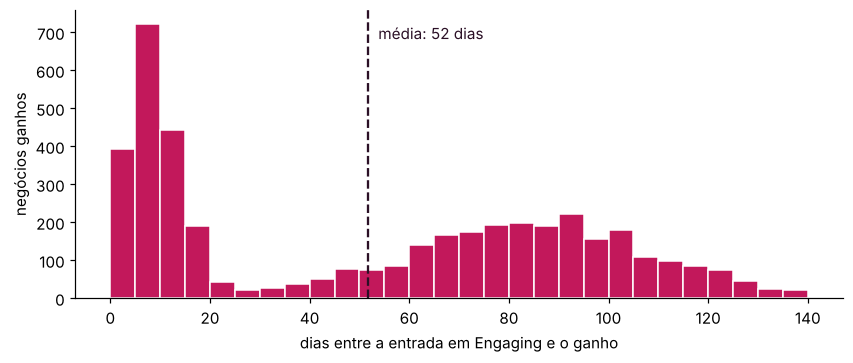

t
(0, 20]     41.600
(20, 45]     4.300
(45, 140]   54.100
Name: proportion, dtype: float64

In [11]:
g = c[c.won == 1]   # só os ganhos
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.hist(g.t, bins=range(0, 145, 5), color=ROSA, edgecolor="white")
ax.axvline(g.t.mean(), color=TINTA, ls="--", lw=1.5)
ax.text(g.t.mean() + 2, ax.get_ylim()[1] * 0.9, f"média: {g.t.mean():.0f} dias", color=TINTA)
ax.set_xlabel("dias entre a entrada em Engaging e o ganho"); ax.set_ylabel("negócios ganhos")
plt.show()
faixas = pd.cut(g.t, [0, 20, 45, 140])
(faixas.value_counts(normalize=True).sort_index() * 100).round(1)

## 4. Três destinos, contando os abertos

Olhar só os ganhos ignora os perdidos e os 1.589 negócios abertos, e muitos desses nunca vão sair do lugar. É como medir o tempo de fila olhando só quem foi atendido.

**Um cuidado com a base:** ela só registra encerramentos entre 01/03/2017 e 31/12/2017. Negócios que entraram antes de março perderam os encerramentos rápidos, e os que entraram em novembro e dezembro perderam os longos. Por isso a curva usa só quem entrou entre 01/03 e 15/08/2017: esses têm os 138 dias completos de observação.

Também separo um bloco atípico da regional Central (entradas de 17/07 a 20/08/2017), tratado na seção 6.

In [12]:
m = e[(e.engage_date >= INI) & (e.engage_date <= FIM - pd.Timedelta(days=138))].copy()
bloco = (m.regional_office == "Central") & m.engage_date.between("2017-07-17", "2017-08-20")
destinos = pd.DataFrame({
    "sem o bloco da Central": m[~bloco].ev.value_counts(normalize=True),
    "com o bloco": m.ev.value_counts(normalize=True),
}).rename(index={1: "ganhos", 2: "perdidos", 0: "parados para sempre"}) * 100
destinos.round(1)

,sem o bloco da Central,com o bloco
ev,,
ganhos,51.400,47.300
perdidos,32.200,30.100
parados para sempre,16.400,22.600


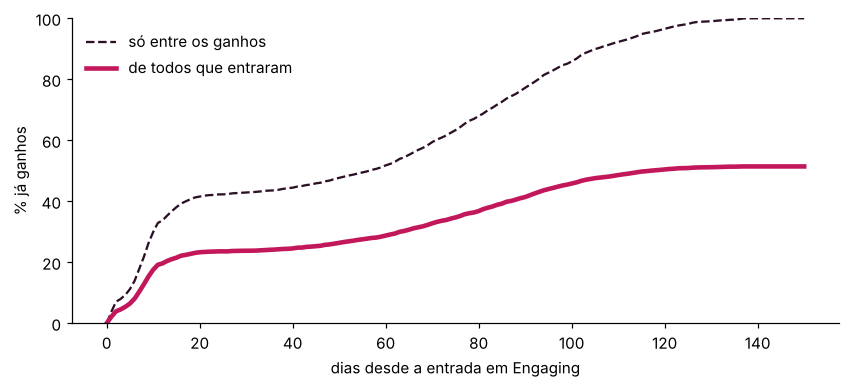

In [13]:
mb = m[~bloco].copy()
dias = np.arange(0, 151)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(dias, [100 * (g.t <= d).mean() for d in dias], color=TINTA, ls="--", label="só entre os ganhos")
ax.plot(dias, [100 * ((mb.ev == 1) & (mb.t <= d)).mean() for d in dias], color=ROSA, lw=3, label="de todos que entraram")
ax.set_ylim(0, 100); ax.set_xlabel("dias desde a entrada em Engaging"); ax.set_ylabel("% já ganhos"); ax.legend(frameon=False)
plt.show()

A pergunta mais útil para quem gerencia o funil: **um negócio aberto há X dias, que chance tem de ser ganho?**

In [14]:
linhas = []
for x in [0, 10, 20, 45, 60, 75, 90, 105, 120, 138]:
    vivo = mb[~(mb.t <= x)]   # ainda abertos com x dias
    linhas.append({"aberto há (dias)": x, "em risco": len(vivo),
                   "é ganho nos próximos 30 dias": ((vivo.ev == 1) & (vivo.t > x) & (vivo.t <= x + 30)).mean(),
                   "é ganho algum dia": (vivo.ev == 1).mean(),
                   "fica parado para sempre": vivo.t.isna().mean()})
pd.DataFrame(linhas).set_index("aberto há (dias)")

,em risco,é ganho nos próximos 30 dias,é ganho algum dia,fica parado para sempre
aberto há (dias),,,,
0,4154,0.238,0.514,0.164
10,2831,0.103,0.497,0.240
20,2416,0.053,0.484,0.281
45,2294,0.170,0.473,0.296
60,2077,0.253,0.454,0.327
75,1698,0.315,0.409,0.400
90,1278,0.294,0.326,0.532
105,920,0.171,0.174,0.739
120,745,0.055,0.055,0.913


O calendário muda a curva: quem entra no primeiro mês do trimestre sai rápido do funil, mas perde mais; quem entra no terceiro ganha mais.

In [15]:
mb["mes_do_trimestre"] = mes_tri(mb.engage_date)
mb.groupby("mes_do_trimestre").agg(negocios=("ev", "size"),
    encerrados_em_20_dias=("t", lambda s: (s <= 20).mean()), encerrados_em_138_dias=("t", lambda s: (s <= 138).mean()),
    ganhos=("ev", lambda s: (s == 1).mean()))

,negocios,encerrados_em_20_dias,encerrados_em_138_dias,ganhos
mes_do_trimestre,,,,
1,1625,0.592,0.855,0.478
2,945,0.291,0.793,0.494
3,1584,0.316,0.843,0.564


## 5. Da chance à receita, e o teste honesto

**O modelo.** Cada negócio aberto, a cada dia, pode ser ganho, perdido ou continuar aberto. A chance de cada destino vem do histórico: entre os negócios que estavam abertos com a mesma idade, no mesmo mês do trimestre, que fração foi ganha ou perdida naquele dia. Avançando dia a dia, sai a chance de o negócio ser ganho em cada mês; multiplicando pelo valor esperado e somando todos, sai a receita do mês. (Nome técnico: modelo de risco em tempo discreto, com riscos concorrentes.)

**O teste.** Em uma data de corte no passado, o modelo usa só o que se sabia até ali e prevê a receita dos meses seguintes. Depois comparo com o real. Os modelos comparados:

- **M0:** pipeline aberto × taxa de ganho histórica (a conta tradicional).
- **M1:** chance por idade do negócio.
- **M2:** chance por idade e mês do trimestre.
- **M3:** gradient boosting com idade e posição no trimestre.

In [16]:
r = rodar(e, "2017-09-30", "2017-12-31", [Naive(), Idade(), IdadeCal(), GBM()])
t = pd.DataFrame({"real": r["real_pipeline"]})
for nome, prev in r["prev"].items():
    if "pipeline" in prev:
        t[nome] = prev["pipeline"].values
t.loc["trimestre"] = t.sum()
print(f"Pipeline aberto em 30/09/2017: {r['n_abertos']} negócios, {r['valor_tabela_abertos']:,.0f} a preço de tabela")
print(f"M0 (pipeline × taxa de ganho), trimestre: {r['prev']['M0 taxa de ganho']['pipeline_total']:,.0f}")
pd.set_option("display.float_format", lambda x: f"{x:,.0f}")
t

Pipeline aberto em 30/09/2017: 2377 negócios, 5,689,123 a preço de tabela
M0 (pipeline × taxa de ganho), trimestre: 3,647,327


,real,M1 idade,M2 idade + calendario,M3 aprendizado de maquina
2017-10,"129,873","856,943","122,530","145,090"
2017-11,"578,711","710,805","903,518","949,091"
2017-12,"508,378","474,714","732,664","705,533"
trimestre,"1,216,962","2,042,462","1,758,712","1,799,714"


Só o modelo com calendário entende que o primeiro mês do trimestre quase não ganha negócio antigo. Mais da metade da receita do trimestre veio de negócios que nem existiam em 30/09:

In [17]:
print(f"receita real do trimestre: {r['real_pipeline'].sum() + r['real_novos'].sum():,.0f}")
print(f"  de negócios abertos em 30/09: {r['real_pipeline'].sum():,.0f}")
print(f"  de negócios que entraram depois: {r['real_novos'].sum():,.0f}")
print(f"  previsão do M2 para essa parte: {r['prev']['M2 idade + calendario']['novos'].sum():,.0f}")

receita real do trimestre: 2,802,496
  de negócios abertos em 30/09: 1,216,962
  de negócios que entraram depois: 1,585,534
  previsão do M2 para essa parte: 1,556,335


Um corte só pode enganar. Repito o teste em sete datas, sempre prevendo o mês seguinte (pipeline mais negócios novos):

In [18]:
linhas = []
for D in pd.date_range("2017-05-31", "2017-11-30", freq="ME"):
    fim = D + pd.offsets.MonthEnd(1)
    rr = rodar(e, D, fim, [Idade(), IdadeCal()])
    real = rr["real_pipeline"].sum() + rr["real_novos"].sum()
    linha = {"corte": D.date(), "real": real}
    for nome, prev in rr["prev"].items():
        linha[nome[:2]] = prev["pipeline"].sum() + prev["novos"].sum()
    linhas.append(linha)
movel = pd.DataFrame(linhas).set_index("corte")
for m_ in ["M1", "M2"]:
    erro = ((movel[m_] - movel.real).abs() / movel.real).mean()
    print(f"{m_}: erro médio {100 * erro:.0f}%")
movel

M1: erro médio 35%
M2: erro médio 18%


,real,M1,M2
corte,,,
2017-05-31,"1,338,466","1,112,242","1,651,378"
2017-06-30,"696,932","1,083,158","625,490"
2017-07-31,"1,050,059","1,399,470","1,228,474"
2017-08-31,"1,235,264","1,094,524","1,594,887"
2017-09-30,"731,980","1,191,268","614,010"
2017-10-31,"938,943","1,236,661","1,150,083"
2017-11-30,"1,131,573","767,648","1,239,765"


**O que não funcionou.** Uma regressão logística de ganho (1) contra perda (0), treinada com os encerrados e com produto, mês de entrada e regional, separa ganho de perda tanto quanto cara ou coroa. Ela também trata todo aberto como se um dia fosse ser encerrado, então repete o erro da conta tradicional. Nesta base, ganhar ou perder depende em grande parte de *quando* o negócio é encerrado.

In [19]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline
e["mq_ent"] = mes_tri(e.engage_date).astype(str)
cols = ["product", "mq_ent", "regional_office"]
D, fim = pd.Timestamp("2017-09-30"), pd.Timestamp("2017-12-31")
treino = e[e.close_date <= D]
abertos = e[(e.engage_date < D) & ~(e.close_date <= D)]
logit = make_pipeline(OneHotEncoder(handle_unknown="ignore"), LogisticRegression(max_iter=2000)).fit(treino[cols], (treino.ev == 1))
encerrou = (abertos.close_date <= fim).values
print("AUC ganho × perdido, entre os encerrados no trimestre:",
      round(roc_auc_score((abertos.ev == 1).values[encerrou], logit.predict_proba(abertos[cols])[encerrou, 1]), 2), "(0,5 = chute)")

AUC ganho × perdido, entre os encerrados no trimestre: 0.49 (0,5 = chute)


## 6. O alarme de pipeline inflado

O maior erro que sobrou vinha de um bloco de negócios que ficaram parados. Não é a empresa toda: é a regional Central, que costuma abrir cerca de 62 negócios por semana e abriu 540 em três semanas. Todos os 408 negócios abertos da Central entraram entre 19/07 e 15/08/2017.

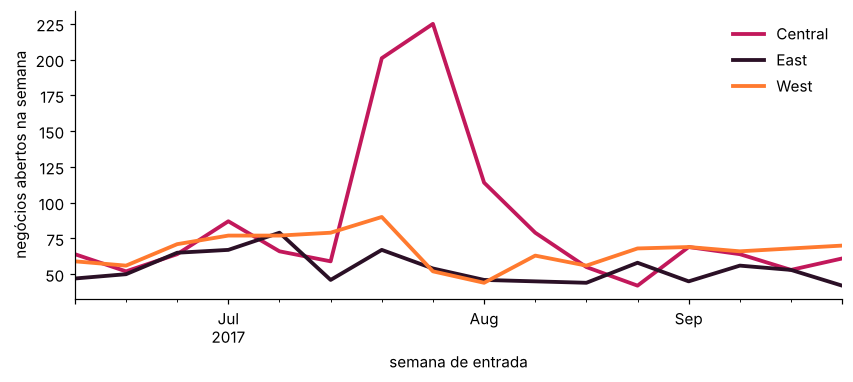

In [20]:
s = e[e.engage_date.between("2017-06-05", "2017-09-24")]
sem = s.groupby([s.engage_date.dt.to_period("W"), "regional_office"]).size().unstack()
ax = sem.plot(figsize=(9, 3.4), color=[ROSA, TINTA, LARANJA], lw=2.5)
ax.set_xlabel("semana de entrada"); ax.set_ylabel("negócios abertos na semana"); ax.legend(frameon=False)
plt.show()

**A regra.** Uma semana de uma regional é marcada quando duas coisas acontecem juntas, usando só o que se sabe na data de corte:

1. as entradas chegam a 1,5 vez ou mais a mediana das oito semanas anteriores da própria regional;
2. a fração encerrada em até 20 dias fica bem abaixo da das outras regionais na mesma semana (teste binomial, p < 0,01).

O excesso estimado é tratado como parado, e a chance dos abertos daquela semana cai na mesma proporção. Sem a primeira condição, a regional West era marcada cinco vezes sem ter pico nenhum.

In [21]:
fator, semanas = detectar(e, "2017-09-30")
marcadas = semanas[semanas.excesso > 0][["wk", "regional_office", "N", "N_normal", "pico", "F", "f_outros", "excesso"]]
print(marcadas.to_string(index=False, float_format=lambda x: f"{x:.2f}"))

                   wk regional_office   N  N_normal  pico  F  f_outros  excesso
2017-07-17/2017-07-23         Central 201     61.50  3.27 70      0.52    65.32
2017-07-24/2017-07-30         Central 225     64.00  3.52 44      0.52   140.20
2017-07-31/2017-08-06         Central 114     65.00  1.75 11      0.31    78.64


In [22]:
linhas = []
for D in pd.date_range("2017-05-31", "2017-11-30", freq="ME"):
    fim = D + pd.offsets.MonthEnd(1)
    rr, base, ajust, fator, _ = rodar_ajustado(e, D, fim)
    novos = rr["prev"]["M2 idade + calendario"]["novos"].sum()
    real = rr["real_pipeline"].sum() + rr["real_novos"].sum()
    linhas.append({"corte": D.date(), "real": real, "M2": base.sum() + novos, "M2 + alarme": ajust.sum() + novos})
aj = pd.DataFrame(linhas).set_index("corte")
for col in ["M2", "M2 + alarme"]:
    print(f"{col}: erro médio {100 * ((aj[col] - aj.real).abs() / aj.real).mean():.0f}% | viés {100 * (aj[col].sum() / aj.real.sum() - 1):+.0f}%")
aj

M2: erro médio 18% | viés +14%
M2 + alarme: erro médio 13% | viés +8%


,real,M2,M2 + alarme
corte,,,
2017-05-31,"1,338,466","1,651,378","1,651,378"
2017-06-30,"696,932","625,490","625,490"
2017-07-31,"1,050,059","1,228,474","1,228,474"
2017-08-31,"1,235,264","1,594,887","1,483,697"
2017-09-30,"731,980","614,010","614,010"
2017-10-31,"938,943","1,150,083","986,770"
2017-11-30,"1,131,573","1,239,765","1,119,102"


## 7. Limitações e próximos passos

- **A base é sintética.** Os padrões (o ritmo trimestral tão regular, a ausência de efeito de porte) são do gerador da base. O método vale; os números são desta empresa fictícia.
- **A janela de encerramentos é cortada nas duas pontas** (01/03 e 31/12/2017), o que obriga a usar só as coortes completas na curva.
- **Não há histórico de atividades** (ligações, reuniões, mudanças de etapa). Com ele, "dias desde o último contato" provavelmente seria a variável mais forte.
- **O campo de conta vazia não foi usado:** todo negócio sem conta está aberto, então ele entrega o resultado final. Num teste retroativo, isso seria usar o futuro.
- **Sete datas de corte é pouco** para afirmar a precisão com segurança.

Próximos passos: a previsão como faixa (com que confiança o real cai dentro dela), uma explicação em linguagem natural para cada negócio em risco, e o teste em uma base real.